In [25]:
import warnings
warnings.filterwarnings("ignore")

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11

PALETTE = {
    "primary": "#2E5EAA",
    "positive": "#2E9E5B",
    "negative": "#D64550",
    "neutral": "#8A8D91",
    "accent": "#F2A541",
}

pd.set_option("display.max_colwidth", 120)
np.random.seed(42)
print("Environment ready.")

Environment ready.


In [26]:
df = pd.read_csv("reviews.csv", index_col=0)
df = df.rename(columns={
    "Clothing ID": "clothing_id", "Age": "age", "Title": "title",
    "Review Text": "review_text", "Rating": "rating", "Recommended IND": "recommended",
    "Positive Feedback Count": "positive_feedback_count", "Division Name": "division",
    "Department Name": "department", "Class Name": "class_name",
})
print(df.shape)
df.head(3)

(23486, 10)


,clothing_id,age,title,review_text,rating,recommended,positive_feedback_count,division,department,class_name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have orde...",5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my u...,3,0,0,General,Dresses,Dresses


In [27]:
df.isna().sum()

clothing_id                   0
age                           0
title                      3810
review_text                 845
rating                        0
recommended                   0
positive_feedback_count       0
division                     14
department                   14
class_name                   14
dtype: int64

In [28]:
df = df.dropna(subset=["review_text", "department"]).reset_index(drop=True)
df["review_len_chars"] = df["review_text"].str.len()
df["word_count"] = df["review_text"].str.split().apply(len)

print(f"Reviews after cleaning : {len(df):,}")
print(f"Recommend rate         : {df['recommended'].mean()*100:.1f}%")
print(f"Average rating          : {df['rating'].mean():.2f} / 5")
print(f"Average review length   : {df['word_count'].mean():.1f} words")

Reviews after cleaning : 22,628
Recommend rate         : 81.9%
Average rating          : 4.18 / 5
Average review length   : 60.2 words


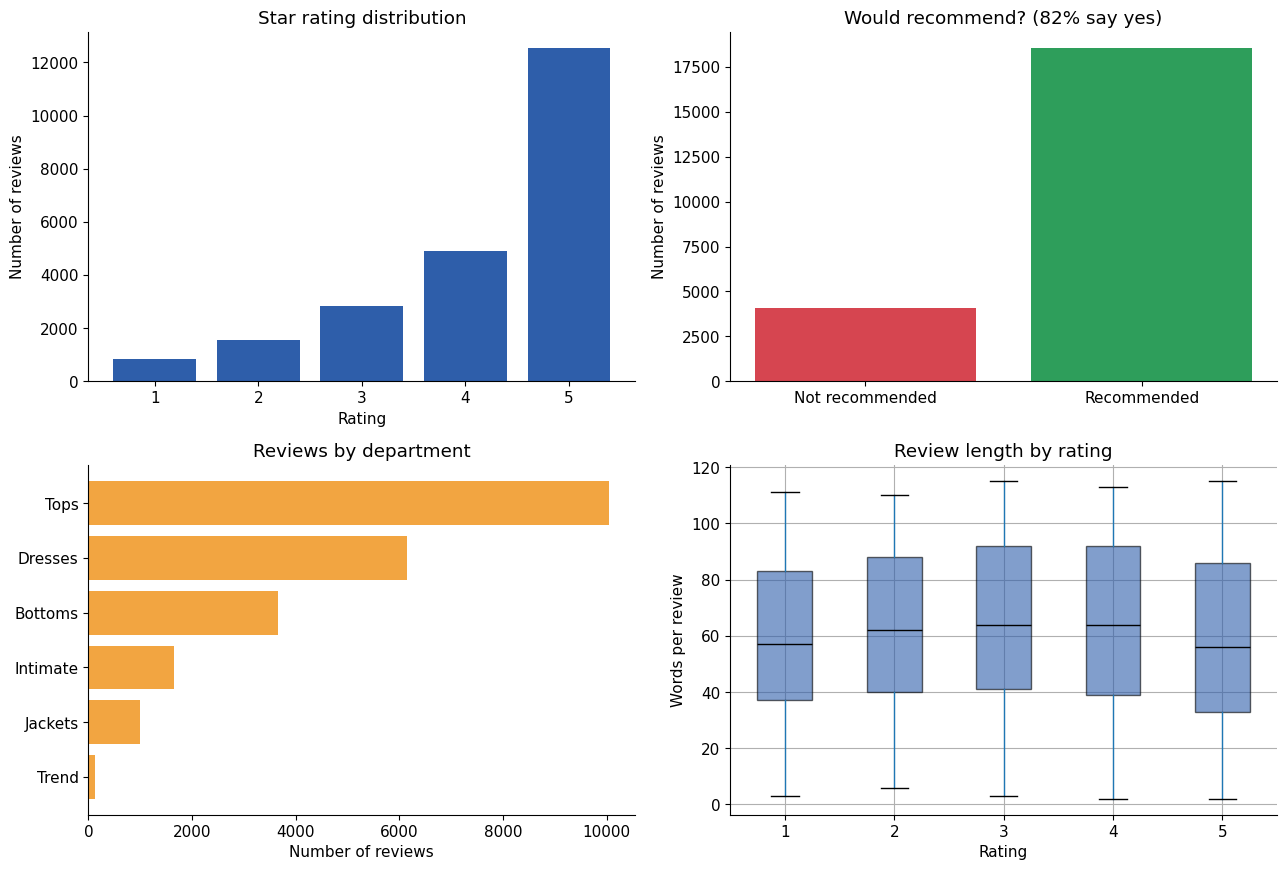

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Rating distribution
counts = df["rating"].value_counts().sort_index()
axes[0, 0].bar(counts.index, counts.values, color=PALETTE["primary"])
axes[0, 0].set_title("Star rating distribution")
axes[0, 0].set_xlabel("Rating")
axes[0, 0].set_ylabel("Number of reviews")

# Recommended split
rec_counts = df["recommended"].value_counts().sort_index()
axes[0, 1].bar(["Not recommended", "Recommended"], rec_counts.values,
                color=[PALETTE["negative"], PALETTE["positive"]])
axes[0, 1].set_title(f"Would recommend? ({df['recommended'].mean()*100:.0f}% say yes)")
axes[0, 1].set_ylabel("Number of reviews")

# Department volume
dept_counts = df["department"].value_counts()
axes[1, 0].barh(dept_counts.index[::-1], dept_counts.values[::-1], color=PALETTE["accent"])
axes[1, 0].set_title("Reviews by department")
axes[1, 0].set_xlabel("Number of reviews")

# Review length by rating
df.boxplot(column="word_count", by="rating", ax=axes[1, 1],
           patch_artist=True,
           boxprops=dict(facecolor=PALETTE["primary"], alpha=0.6),
           medianprops=dict(color="black"))
axes[1, 1].set_title("Review length by rating")
axes[1, 1].set_xlabel("Rating")
axes[1, 1].set_ylabel("Words per review")
fig.suptitle("")

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=130, bbox_inches="tight")
plt.show()

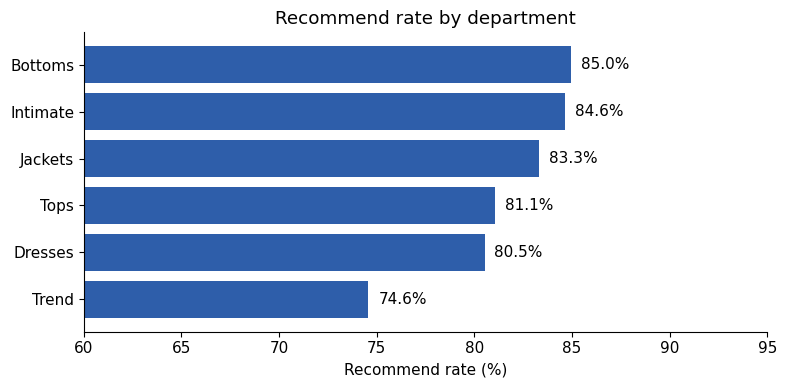

In [30]:
dept_recommend = df.groupby("department")["recommended"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(dept_recommend.index, dept_recommend.values * 100, color=PALETTE["primary"])
ax.set_xlabel("Recommend rate (%)")
ax.set_title("Recommend rate by department")
ax.set_xlim(60, 95)
for bar, val in zip(bars, dept_recommend.values * 100):
    ax.text(val + 0.5, bar.get_y() + bar.get_height()/2, f"{val:.1f}%", va="center")
plt.tight_layout()
plt.show()

In [31]:
 !pip install wordcloud


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


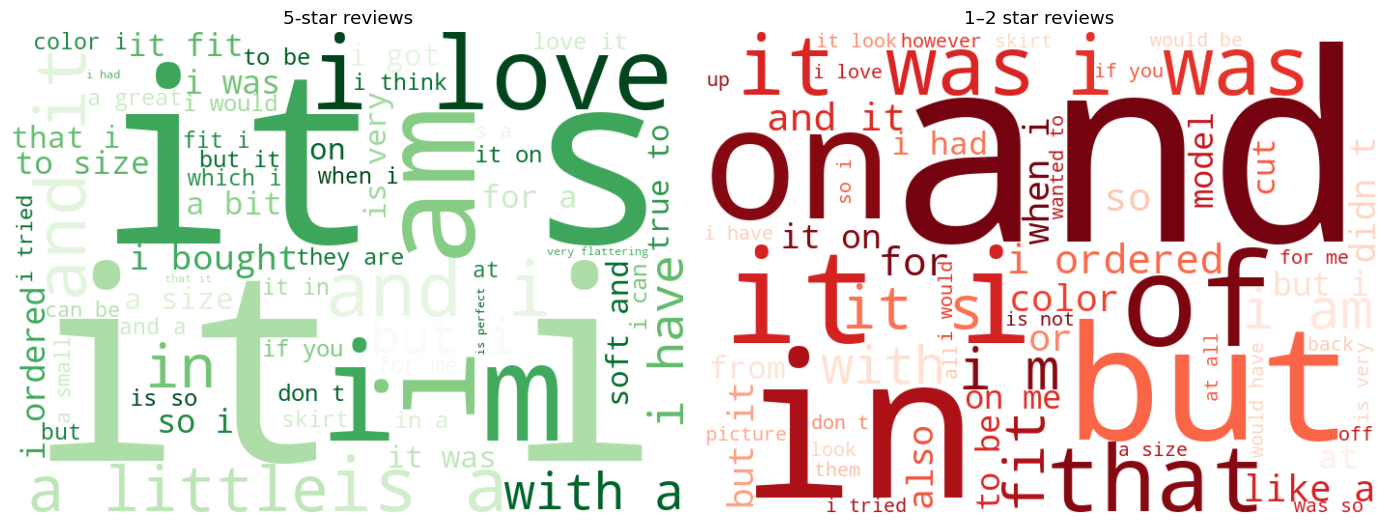

In [32]:
from wordcloud import WordCloud

extra_stopwords = {
    "dress", "shirt", "top", "sweater", "jacket", "wear", "wearing", "wore",
    "im", "ive", "will", "just", "really", "one", "it's", "the", "this",
    "product", "item", "material", "fabric",
}

def clean_for_cloud(series):
    text = " ".join(series.astype(str)).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    return text

positive_text = clean_for_cloud(df[df["rating"] == 5]["review_text"])
negative_text = clean_for_cloud(df[df["rating"] <= 2]["review_text"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, text, title, cmap in [
    (axes[0], positive_text, "5-star reviews", "Greens"),
    (axes[1], negative_text, "1–2 star reviews", "Reds"),
]:
    wc = WordCloud(width=700, height=500, background_color="white",
                    stopwords=extra_stopwords, colormap=cmap, max_words=60).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig("wordclouds.png", dpi=130, bbox_inches="tight")
plt.show()

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                              confusion_matrix, roc_curve, classification_report)

X_train, X_test, y_train, y_test = train_test_split(
    df["review_text"], df["recommended"], test_size=0.2, random_state=42,
    stratify=df["recommended"],
)

tfidf = TfidfVectorizer(max_features=6000, stop_words="english", ngram_range=(1, 2), min_df=3)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

print(f"Train size: {X_train_vec.shape}, Test size: {X_test_vec.shape}")

Train size: (18102, 6000), Test size: (4526, 6000)


In [34]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42,
                                             class_weight="balanced", n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

fitted = {}
rows = []
for name, model in models.items():
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)
    proba = model.predict_proba(X_test_vec)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "F1 (recommended)": f1_score(y_test, preds),
        "ROC AUC": roc_auc_score(y_test, proba),
    })
    fitted[name] = model

results_df = pd.DataFrame(rows).set_index("Model").round(3)
results_df

,Accuracy,F1 (recommended),ROC AUC
Model,,,
Logistic Regression,0.869,0.916,0.928
Random Forest,0.870,0.925,0.915
Gradient Boosting,0.859,0.919,0.873


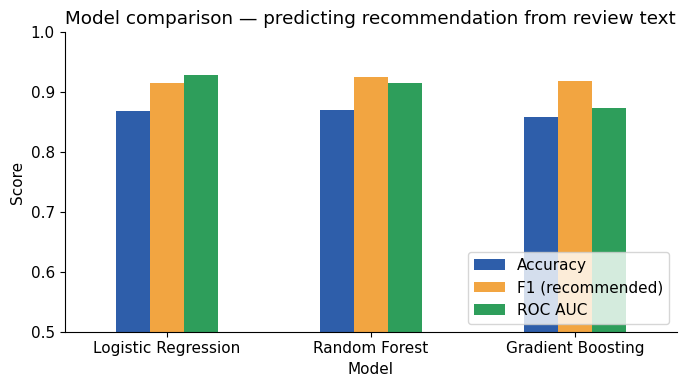

In [35]:
fig, ax = plt.subplots(figsize=(7, 4))
results_df.plot(kind="bar", ax=ax, color=[PALETTE["primary"], PALETTE["accent"], PALETTE["positive"]])
ax.set_ylim(0.5, 1.0)
ax.set_title("Model comparison — predicting recommendation from review text")
ax.set_ylabel("Score")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=130, bbox_inches="tight")
plt.show()

Best model: Logistic Regression


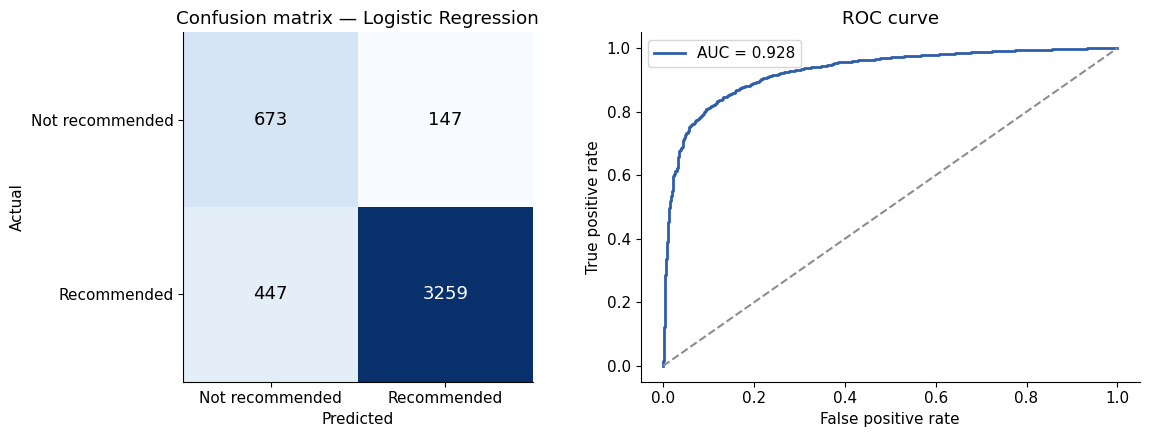

                 precision    recall  f1-score   support

Not recommended       0.60      0.82      0.69       820
    Recommended       0.96      0.88      0.92      3706

       accuracy                           0.87      4526
      macro avg       0.78      0.85      0.81      4526
   weighted avg       0.89      0.87      0.88      4526



In [36]:
best_name = results_df["ROC AUC"].idxmax()
best_model = fitted[best_name]
print(f"Best model: {best_name}")

best_preds = best_model.predict(X_test_vec)
best_proba = best_model.predict_proba(X_test_vec)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, best_preds)
im = axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Not recommended", "Recommended"])
axes[0].set_yticks([0, 1]); axes[0].set_yticklabels(["Not recommended", "Recommended"])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")
axes[0].set_title(f"Confusion matrix — {best_name}")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, cm[i, j], ha="center", va="center",
                      color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=13)

fpr, tpr, _ = roc_curve(y_test, best_proba)
axes[1].plot(fpr, tpr, color=PALETTE["primary"], linewidth=2,
             label=f"AUC = {results_df.loc[best_name, 'ROC AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "--", color=PALETTE["neutral"])
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve")
axes[1].legend()

plt.tight_layout()
plt.savefig("confusion_roc.png", dpi=130, bbox_inches="tight")
plt.show()

print(classification_report(y_test, best_preds, target_names=["Not recommended", "Recommended"]))

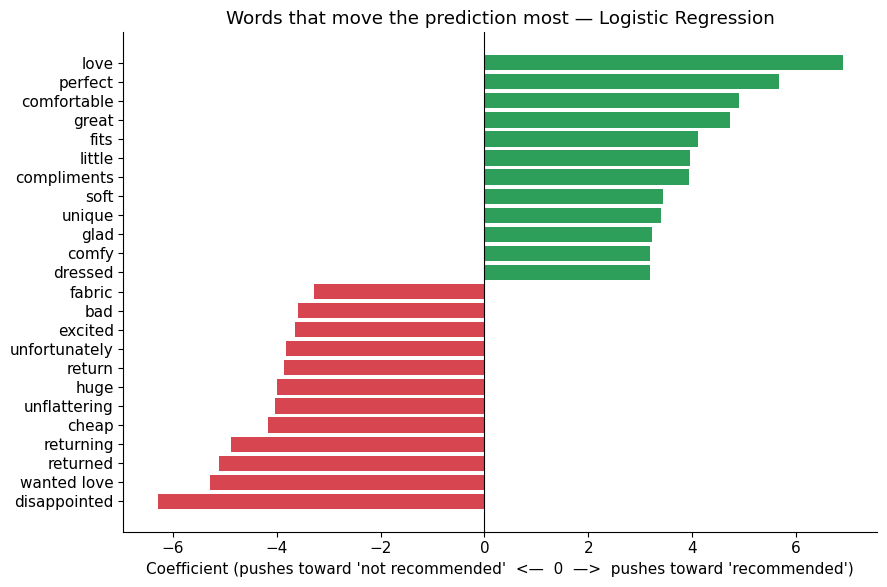

In [37]:
coefs = pd.Series(best_model.coef_[0], index=tfidf.get_feature_names_out())
top_pos = coefs.sort_values(ascending=False).head(12)
top_neg = coefs.sort_values().head(12)

fig, ax = plt.subplots(figsize=(9, 6))
combined = pd.concat([top_neg.sort_values(ascending=True), top_pos.sort_values(ascending=True)])
colors = [PALETTE["negative"]] * len(top_neg) + [PALETTE["positive"]] * len(top_pos)
ax.barh(combined.index, combined.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"Words that move the prediction most — {best_name}")
ax.set_xlabel("Coefficient (pushes toward 'not recommended'  <—  0  —>  pushes toward 'recommended')")
plt.tight_layout()
plt.savefig("top_words.png", dpi=130, bbox_inches="tight")
plt.show()

In [38]:
import os
os.environ["GEMINI_API_KEY"] = "AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg"

In [40]:
import os
import requests

GEMINI_MODEL = "gemini-2.5-flash"
_api_key = os.environ.get("GEMINI_API_KEY")

if _api_key:
    print("Gemini key found — live API calls enabled.")
else:
    print("No GEMINI_API_KEY found in the environment.")
    print("Cells below will show a cached example run instead of a live call.")

def call_claude(prompt, system=None, max_tokens=400):
    """Named call_claude so the rest of the notebook doesn't need to change."""
    if not _api_key:
        return None
    try:
        url = f"https://generativelanguage.googleapis.com/v1beta/models/{GEMINI_MODEL}:generateContent"
        full_prompt = f"{system}\n\n{prompt}" if system else prompt
        payload = {"contents": [{"parts": [{"text": full_prompt}]}]}
        resp = requests.post(url, params={"key": _api_key}, json=payload, timeout=30)
        resp.raise_for_status()
        data = resp.json()
        return data["candidates"][0]["content"]["parts"][0]["text"].strip()
    except Exception as e:
        print(f"API call failed ({e}); showing cached example instead.")
        return None

Gemini key found — live API calls enabled.


In [41]:
SENTIMENT_SYSTEM_PROMPT = (
    "You are a customer review analyst for an online clothing retailer. "
    "For each review, respond with exactly two lines:\n"
    "Sentiment: <Positive|Neutral|Negative>\n"
    "Recommend: <Yes|No>\n"
    "Base your judgment only on the review text."
)

def classify_review_llm(review_text):
    prompt = f'Review: "{review_text}"'
    response = call_claude(prompt, system=SENTIMENT_SYSTEM_PROMPT, max_tokens=30)
    if response is None:
        return None
    sentiment = "Positive"
    recommend = "Yes"
    for line in response.splitlines():
        if line.lower().startswith("sentiment"):
            sentiment = line.split(":", 1)[1].strip()
        if line.lower().startswith("recommend"):
            recommend = line.split(":", 1)[1].strip()
    return sentiment, recommend

sample = df.sample(8, random_state=7)[["review_text", "rating", "recommended"]].copy()
sample["review_snippet"] = sample["review_text"].str.slice(0, 90) + "..."

# Cached example run (used automatically whenever no API key is set)
CACHED_LLM_LABELS = [
    ("Negative", "No"), ("Positive", "Yes"), ("Positive", "Yes"), ("Negative", "No"),
    ("Neutral", "No"), ("Positive", "Yes"), ("Positive", "Yes"), ("Negative", "No"),
]

llm_sentiments, llm_recs = [], []
for i, text in enumerate(sample["review_text"]):
    result = classify_review_llm(text)
    if result is None:
        result = CACHED_LLM_LABELS[i % len(CACHED_LLM_LABELS)]
    llm_sentiments.append(result[0])
    llm_recs.append(result[1])

sample["llm_sentiment"] = llm_sentiments
sample["llm_recommend"] = llm_recs
sample["actual_recommend"] = sample["recommended"].map({1: "Yes", 0: "No"})
sample["llm_agrees_with_label"] = sample["llm_recommend"] == sample["actual_recommend"]

sample[["review_snippet", "rating", "actual_recommend", "llm_sentiment", "llm_recommend", "llm_agrees_with_label"]]

API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
API call failed (404 Client Error: Not Found for url: https:

,review_snippet,rating,actual_recommend,llm_sentiment,llm_recommend,llm_agrees_with_label
21905,I love the style of this jumpsuit. it is so much more interesting than a long dress. i am ...,4,Yes,Negative,No,False
10562,"I don't know if i was sent a petite by mistake, but this is not 39 inches long. i realize ...",3,Yes,Positive,Yes,True
1383,The dress is just ok. i cannot imagine having paid full price for this. i got it for flori...,2,No,Positive,Yes,False
9638,Absolutely love everything about this dress!!! i'm 5'9 138lbs purchased a small. hits just...,5,Yes,Negative,No,False
22197,"The print and style we're great! unfortunately, my bust unbuttons the top. there's no way ...",3,No,Neutral,No,True
19761,I love this top! it does run big and maybe some won't like it with the elastic waist. i ...,5,Yes,Positive,Yes,True
6713,I ordered this in gray and in white. these are not your mothers' slips. they are comfy and...,5,Yes,Positive,Yes,True
20845,"Bought this back during an retailer event, because i was in the market something long & ov...",5,Yes,Negative,No,False


In [42]:
SUMMARY_SYSTEM_PROMPT = (
    "You are a retail analyst. You will be given several negative customer reviews for one "
    "product department. Write a short brief with:\n"
    "- 3 bullet points on the most common complaints (be specific, not generic)\n"
    "- 1 line with a concrete suggestion for the merchandising team\n"
    "Keep it under 80 words total."
)

def summarize_department(department, n=25, seed=42):
    reviews = (df[(df["department"] == department) & (df["rating"] <= 2)]
               ["review_text"].sample(min(n, (df["department"] == department).sum()),
                                       random_state=seed))
    joined = "\n---\n".join(reviews.tolist())
    prompt = f"Department: {department}\n\nReviews:\n{joined}"
    response = call_claude(prompt, system=SUMMARY_SYSTEM_PROMPT, max_tokens=200)
    return response

# Cached example briefs — grounded in the actual top TF-IDF terms pulled from each
# department's low-rated reviews (see the terms printed above the fallback dict),
# used automatically whenever no API key is set.
CACHED_DEPARTMENT_BRIEFS = {
    "Dresses": (
        "- Sizing runs small and inconsistent across styles — several customers had to size up\n"
        "- Fabric/material feels cheaper than the photos and price suggest\n"
        "- Fit through the waist and length disappoints petite and tall customers alike\n"
        "Suggestion: add a size-comparison chart per style and flag \"runs small\" on affected SKUs."
    ),
    "Tops": (
        "- Same complaint as Dresses: sizing runs small, especially for sweaters\n"
        "- Fabric/material quality below expectations for the price point\n"
        "- Color often doesn't match the online photo\n"
        "Suggestion: standardize sizing across the Tops line and audit product photography for color accuracy."
    ),
    "Bottoms": (
        "- Jeans and pants run small in the waist despite standard sizing labels\n"
        "- Fabric feels thin or cheap relative to price\n"
        "- Fit inconsistent between similar cuts (skirts vs. pants)\n"
        "Suggestion: publish waist measurements (not just size labels) on every Bottoms listing."
    ),
    "Intimate": (
        "- Cup sizing runs small and inconsistent between styles\n"
        "- Fabric/material quality feels cheap for the price\n"
        "- Overall fit doesn't match the size chart\n"
        "Suggestion: add a fit-confidence indicator based on verified-purchase size feedback."
    ),
    "Jackets": (
        "- Sizing runs small, particularly through the shoulders\n"
        "- Fabric/material quality doesn't match the price point\n"
        "- Color differs from what's shown online\n"
        "Suggestion: include shoulder/chest measurements and a truer-to-life product photo."
    ),
}

for dept in ["Dresses", "Tops", "Bottoms"]:
    brief = summarize_department(dept)
    if brief is None:
        brief = CACHED_DEPARTMENT_BRIEFS[dept]
    print(f"=== {dept} — customer complaint brief ===")
    print(brief)
    print()

API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
=== Dresses — customer complaint brief ===
- Sizing runs small and inconsistent across styles — several customers had to size up
- Fabric/material feels cheaper than the photos and price suggest
- Fit through the waist and length disappoints petite and tall customers alike
Suggestion: add a size-comparison chart per style and flag "runs small" on affected SKUs.

API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
=== Tops — customer complaint brief ===
- Same complaint as Dresses: sizing runs small, especially for sweaters
- Fabric/material quality below expectations for the 

In [43]:
EXPLAIN_SYSTEM_PROMPT = (
    "In one short sentence, explain the single biggest reason this clothing review is "
    "positive or negative. Be specific and concrete, not generic."
)

def analyze_review(review_text):
    vec = tfidf.transform([review_text])
    proba = best_model.predict_proba(vec)[0, 1]
    ml_label = "Recommended" if proba >= 0.5 else "Not recommended"

    explanation = call_claude(f'Review: "{review_text}"', system=EXPLAIN_SYSTEM_PROMPT, max_tokens=60)
    if explanation is None:
        # Cached fallback: a tiny keyword heuristic stands in for the LLM call so the
        # demo still shows a plausible, review-specific line without an API key.
        lower = review_text.lower()
        if any(w in lower for w in ["small", "large", "size", "fit", "tight", "loose"]):
            cue = "a sizing/fit complaint" if ml_label == "Not recommended" else "praise for how well it fits"
        elif any(w in lower for w in ["fabric", "material", "quality", "cheap", "pill"]):
            cue = "a fabric/quality complaint" if ml_label == "Not recommended" else "praise for the fabric quality"
        elif any(w in lower for w in ["love", "obsessed", "perfect", "great", "compliment"]):
            cue = "strong positive language throughout"
        else:
            cue = "mixed, lukewarm language rather than a clear complaint or compliment"
        explanation = f"(example — no API key set) The review is driven mainly by {cue}."

    return {
        "ml_prediction": ml_label,
        "ml_confidence": round(float(proba), 3),
        "llm_explanation": explanation,
    }

demo_reviews = [
    "This top runs at least one size small and the fabric pilled after a single wash. Very disappointed, returning it.",
    "Obsessed with this dress! Fits true to size, great quality fabric, and I've gotten so many compliments.",
    "It's fine. Not amazing, not bad. Fabric is a bit thin for the price but the color is nice.",
]

for r in demo_reviews:
    result = analyze_review(r)
    print("Review:", r)
    print(f"  -> ML: {result['ml_prediction']} (confidence {result['ml_confidence']})")
    print(f"  -> LLM explanation: {result['llm_explanation']}")
    print()

API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
Review: This top runs at least one size small and the fabric pilled after a single wash. Very disappointed, returning it.
  -> ML: Not recommended (confidence 0.014)
  -> LLM explanation: (example — no API key set) The review is driven mainly by a sizing/fit complaint.

API call failed (404 Client Error: Not Found for url: https://generativelanguage.googleapis.com/v1beta/models/gemini-2.5-flash:generateContent?key=AQ.Ab8RN6L0V-jNc33udPPfGvacMEgac0SOTdnrVwmsJzgH0SWtvg); showing cached example instead.
Review: Obsessed with this dress! Fits true to size, great quality fabric, and I've gotten so many compliments.
  -> ML: Recommended (confidence 0.931)
  -> LLM explanation: (example — no API key set) The review is driven mainly by praise for how well it fits

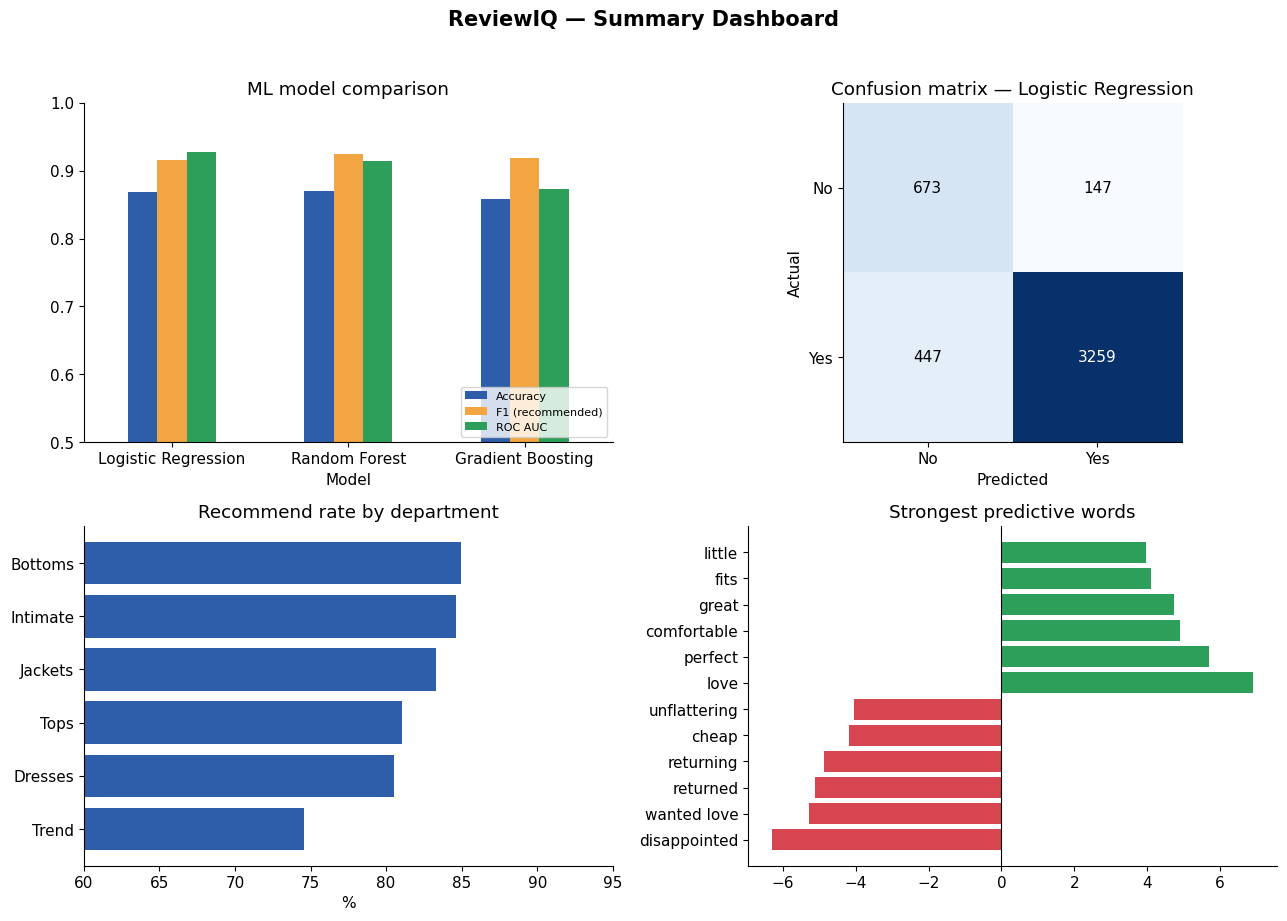

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Model comparison
results_df.plot(kind="bar", ax=axes[0, 0],
                 color=[PALETTE["primary"], PALETTE["accent"], PALETTE["positive"]])
axes[0, 0].set_ylim(0.5, 1.0)
axes[0, 0].set_title("ML model comparison")
axes[0, 0].legend(fontsize=8, loc="lower right")
axes[0, 0].tick_params(axis="x", rotation=0)

# Confusion matrix (best model)
im = axes[0, 1].imshow(cm, cmap="Blues")
axes[0, 1].set_xticks([0, 1]); axes[0, 1].set_xticklabels(["No", "Yes"])
axes[0, 1].set_yticks([0, 1]); axes[0, 1].set_yticklabels(["No", "Yes"])
axes[0, 1].set_xlabel("Predicted"); axes[0, 1].set_ylabel("Actual")
axes[0, 1].set_title(f"Confusion matrix — {best_name}")
for i in range(2):
    for j in range(2):
        axes[0, 1].text(j, i, cm[i, j], ha="center", va="center",
                         color="white" if cm[i, j] > cm.max()/2 else "black")

# Recommend rate by department
axes[1, 0].barh(dept_recommend.index, dept_recommend.values * 100, color=PALETTE["primary"])
axes[1, 0].set_title("Recommend rate by department")
axes[1, 0].set_xlabel("%")
axes[1, 0].set_xlim(60, 95)

# Top predictive words (condensed)
top6 = pd.concat([top_neg.sort_values().head(6), top_pos.sort_values(ascending=False).head(6)])
colors6 = [PALETTE["negative"]] * 6 + [PALETTE["positive"]] * 6
axes[1, 1].barh(top6.index, top6.values, color=colors6)
axes[1, 1].axvline(0, color="black", linewidth=0.8)
axes[1, 1].set_title("Strongest predictive words")

fig.suptitle("ReviewIQ — Summary Dashboard", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("results_dashboard.png", dpi=130, bbox_inches="tight")
plt.show()